# Финальный проект: Разработка ML-модели для классификации способов передвижения пользователя по датчикам Android устройства

## Постановка задачи и анализ предметной области

### Бизнес-контекст и цель

Я создаю систему, которая автоматически определяет, как перемещается пользователь (пешком, в машине, автобусе, поезде или стоит на месте), используя только сигналы с сенсоров его Android смартфона. В коммерческих приложениях это нужно для автоматического переключения режимов (например, энергосбережение при остановке, фитнес-трекинг при ходьбе или предложение навигации в автомобиле) без участия самого человека.

Использование машинного обучения здесь необходимо т.к., данные с датчиков (ускорение, вращение, скорость, звук) шумные, частотные и сильно переплетены. Построить жесткие логические правила вручную для пяти разных классов передвижения просто невозможно.

### Тип задачи и метрики

Это задача мультиклассовой классификации (5 сбалансированных классов).
В качестве целевых метрик оцениваем:
- **Accuracy** - базовая точность (так как классы идеально сбалансированы).
- **Macro F1-score** - баланс точности и полноты по каждому классу без перекосов.
- **ROC-AUC** - качество ранжирования вероятностей по каждому классу.

### Допущения и ограничения

1. *Задержка окна* - данные агрегируются за 5-секундные срезы. Это значит, что модель узнает об изменении режима движения с задержкой до 5 секунд.
2. *Физическое положение телефона* - предполагаем, что телефон жестко связан с движением (в кармане или в руке). Если телефон лежит свободно на сиденье автомобиля, профиль вибраций будет другим.
3. *Автономность* - модель должна быть легкой, чтобы работать прямо на мобильном устройстве и не разряжать его батарею.

## Сбор, подготовка и анализ данных

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("raw/Dthird.csv") 

df.head().T 

,0,1,2,3,4
time,78.0,145.0,150.0,105.0,77.0
android.sensor.accelerometer#mean,9.811476,9.939207,9.827178,9.673039,9.993466
android.sensor.accelerometer#min,9.758895,7.707437,9.804817,7.659674,8.965621
android.sensor.accelerometer#max,9.849411,17.146631,9.849262,12.304298,10.891645
android.sensor.accelerometer#std,0.014626,1.775944,0.011199,0.862553,0.504117
android.sensor.game_rotation_vector#mean,0.02934,0.999925,0.665215,0.996221,0.563792
android.sensor.game_rotation_vector#min,0.029014,0.999903,0.665213,0.993781,0.521799
android.sensor.game_rotation_vector#max,0.029526,0.999946,0.665218,0.998661,0.672664
android.sensor.game_rotation_vector#std,0.000119,0.00003,0.000004,0.003451,0.064792
android.sensor.gyroscope#mean,0.001651,0.036326,0.001525,0.03644,0.183202


### Источники, объём и структура данных

In [3]:
print(df.info())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5893 entries, 0 to 5892
Data columns (total 38 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   time                                        5893 non-null   float64
 1   android.sensor.accelerometer#mean           5893 non-null   float64
 2   android.sensor.accelerometer#min            5893 non-null   float64
 3   android.sensor.accelerometer#max            5893 non-null   float64
 4   android.sensor.accelerometer#std            5893 non-null   float64
 5   android.sensor.game_rotation_vector#mean    5893 non-null   float64
 6   android.sensor.game_rotation_vector#min     5893 non-null   float64
 7   android.sensor.game_rotation_vector#max     5893 non-null   float64
 8   android.sensor.game_rotation_vector#std     5893 non-null   float64
 9   android.sensor.gyroscope#mean               5893 non-null   float64
 10  android.sens

Датасет, с которым я буду работать - **TMD Dataset (5 seconds sliding window)** с платформы Kaggle (https://www.kaggle.com/datasets/fschwartzer/tmd-dataset-5-seconds-sliding-window/data). В нём собраны показания сенсоров с Android-смартфонов. Все данные разбиты на пятисекундные отрезки.

В таблице **5893** записи и **38** колонок (37 признаков плюс целевая переменная). На диске файл весит около 2,8 МБ, а после загрузки в pandas занимает в памяти всего 1,7 МБ.

Для каждого датчика разработчики уже рассчитали по 4 базовых показателя на пятисекундных интервалах: среднее значение (`#mean`), минимум (`#min`), максимум (`#max`) и стандартное отклонение (`#std`).

Все признаки (кроме таргета) числовые (`float64`). 

### Что из себя представляют эти данные

1. `time` - timestamp. В описании датасета на Kaggle он четко не описан. Думаю, что его можно удалить, т.к. это лишний шум в данных.
2. `android.sensor.accelerometer` - Измеряет ускорение устройства по трем осям (X, Y, Z), включая силу тяжести. Помогает определять ориентацию экрана и фиксировать встряхивания.
3. `android.sensor.game_rotation_vector` - Похож на обычный вектор вращения, но не использует магнетометр. Это избавляет от помех со стороны металлических предметов.
4. `android.sensor.gyroscope` - Измеряет скорость вращения устройства вокруг трех осей.
5. `android.sensor.gyroscope_uncalibrated` - Предоставляет данные о вращении без применения заводских или пользовательских корректировок дрейфа. Дублирует данные с гироскопа. Оставлю для демонстрации прунинга.
6. `android.sensor.linear_acceleration` - Тот же акселерометр, но с программно отфильтрованной гравитацией. Показывает только "чистое" ускорение при перемещении устройства. Дублириует признак обычного акселерометра, но его я оставлю, чтобы в будущем можно было применить прунинг.
7. `android.sensor.orientation` - Устаревший тип данных, показывающий углы наклона и поворота. Очень нестабильный + может давать резкие (для нейросети) повороты (359 - 1 градус). Его я тоже удалю.
8. `android.sensor.rotation_vector` - Комбинирует данные акселерометра, гироскопа и магнетометра для определения точного положения устройства в пространстве относительно сторон света.
9. `sound` - Измеряет уровень звукового давления (громкость) через микрофон.
10. `speed` - Определяет скорость перемещения устройства, обычно на основе данных GPS или сетевых координат.
11. `target` - Целевая переменная на основе которой будет происходить обучение модели. Содержит информацию о состоянии передвижения пользователя (неподвижный, ходьба, авто и т.д.).

### Целевая переменная

In [4]:
df["target"].unique()

array(['Still', 'Car', 'Train', 'Bus', 'Walking'], dtype=object)

В колонке `target` записано, как именно перемещался пользователь в момент замера. Здесь всего пять классов:

- **Still** - пользователь стоит, сидит или положил телефон на стол.
- **Walking** - обычная ходьба.
- **Car** - поездка на легковой машине. 
- **Bus** - поездка на автобусе.
- **Train** - поезд или метро. 

### Работа с данными

Для начала удалю лишние признаки.

In [5]:
# Удаляю неугодные признаки
df = df.drop(["time", "android.sensor.orientation#min", "android.sensor.orientation#max", "android.sensor.orientation#mean", "android.sensor.orientation#std"], axis=1)

Проверю датасет на баланс классов в таргете и пропущенные значения.

In [6]:
# Проверка на баланс классов

df["target"].value_counts()

target
Car        1180
Still      1179
Train      1179
Bus        1178
Walking    1177
Name: count, dtype: int64

Классы в таргете практически идеально сбалансированы!

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5893 entries, 0 to 5892
Data columns (total 33 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   android.sensor.accelerometer#mean           5893 non-null   float64
 1   android.sensor.accelerometer#min            5893 non-null   float64
 2   android.sensor.accelerometer#max            5893 non-null   float64
 3   android.sensor.accelerometer#std            5893 non-null   float64
 4   android.sensor.game_rotation_vector#mean    5893 non-null   float64
 5   android.sensor.game_rotation_vector#min     5893 non-null   float64
 6   android.sensor.game_rotation_vector#max     5893 non-null   float64
 7   android.sensor.game_rotation_vector#std     5893 non-null   float64
 8   android.sensor.gyroscope#mean               5893 non-null   float64
 9   android.sensor.gyroscope#min                5893 non-null   float64
 10  android.sens

Пропущенных значений нет, все признаки в приемлемых типах данных.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
android.sensor.accelerometer#mean,5893.0,10.007976,0.655949,7.369055,9.737143,9.850143,10.078998,17.427391
android.sensor.accelerometer#min,5893.0,8.426262,1.783007,0.337166,7.805295,9.123124,9.691731,12.115013
android.sensor.accelerometer#max,5893.0,12.247691,5.178436,8.801019,10.015566,10.602081,12.291575,66.886376
android.sensor.accelerometer#std,5893.0,0.982987,1.505615,0.001286,0.078055,0.369163,1.058376,12.879851
android.sensor.game_rotation_vector#mean,5893.0,0.656334,0.349446,0.000000,0.443915,0.779667,0.956667,1.000000
android.sensor.game_rotation_vector#min,5893.0,0.643014,0.348100,0.000000,0.414411,0.750004,0.951903,1.000000
android.sensor.game_rotation_vector#max,5893.0,0.667008,0.352741,0.000000,0.459807,0.803979,0.962301,1.000000
android.sensor.game_rotation_vector#std,5893.0,0.010264,0.025104,0.000000,0.000073,0.001083,0.007644,0.324466
android.sensor.gyroscope#mean,5893.0,0.274351,0.529583,0.000000,0.007377,0.035267,0.205268,5.662153
android.sensor.gyroscope#min,5893.0,0.078560,0.195519,0.000000,0.002044,0.008777,0.054033,3.232744


`speed` часто имеет значение, равное 0. Это значит, что GPS не включен. `sound` - тоже имеет 0 значения, но на практике это невозможно - микрофоны всегда будут фиксировать как минимум белый шум - это значит, что микрофон тоже может быть отключеным.

Создам булевые флаги `is_gps_active` и `is_mic_active`.

In [9]:
df["is_gps_active"] = (df["speed#mean"] > 0).astype(int)
df["is_mic_active"] = (df["sound#mean"] > 0).astype(int)

### Обоснование фичеринжиниринга и влияние на качество

Я создал два бинарных флага: `is_gps_active` и `is_mic_active`. В реальных условиях люди часто отключают геолокацию или запрещают доступ к микрофону. В этих случаях датчики скорости и звука выдают ровно 0. Обычное масштабирование превратит эти нули в ложные значения, которые запутают модель. Бинарные флаги явно сообщают модели, что в данный момент этот датчик отключен и его показания стоит игнорировать. Это повышает устойчивость модели к отсутствию данных и предотвращает искажение вещественных признаков при стандартизации.

Теперь посмотрю на распределение признаков по классам и всему датасету в целом.

In [10]:
features = set([x[:x.index("#")] for x in df.drop(["target", "is_gps_active", "is_mic_active"], axis=1).columns])
features

{'android.sensor.accelerometer',
 'android.sensor.game_rotation_vector',
 'android.sensor.gyroscope',
 'android.sensor.gyroscope_uncalibrated',
 'android.sensor.linear_acceleration',
 'android.sensor.rotation_vector',
 'sound',
 'speed'}

In [11]:
def draw_plot(dataset: pd.DataFrame, feature_to_plot: str, title: str = None, figsize: tuple = None) -> None:
    """
    Рисует гистограммы распределений показаний #mean, #max, #min признака по каждому классу и всему датасету.

    Args:
        dataset (pandas.DataFrame): Датафрейм, по которому будет нарисован график.
        feature_to_plot (str): Название признака
        title (str, optional): Заголовок холста
        figsize (tuple, optional): Размер холста
    """

    figsize = (13, 8) if figsize is None else figsize

    fig, axes = plt.subplots(2,3, figsize=figsize)
    axes_flatten = axes.flatten()

    def plot_hist(dataset: pd.DataFrame, ax):
        for suffix, color in [("mean", "blue"), ("max", "orange"), ("min", "green")]:
            sns.histplot(dataset[f"{feature_to_plot}#{suffix}"], fill=True, color=color, kde=True, ax=ax, label=suffix)

    def make_subplot(dataset: pd.DataFrame, title: str, ax_index: int):
        ax = axes_flatten[ax_index]

        plot_hist(dataset, ax)

        ax.set_title(title)
        ax.set_xlabel(feature_to_plot)
        ax.legend()

    for i, target_class in enumerate(dataset["target"].unique()):
        make_subplot(dataset[dataset["target"] == target_class], title=target_class, ax_index=i)

    make_subplot(dataset, title="Across all targets", ax_index=i+1)

    title = f"{feature_to_plot} feature distribution across target classes" if title is None else title
    fig.suptitle(title)
        
    plt.tight_layout()
    plt.show()

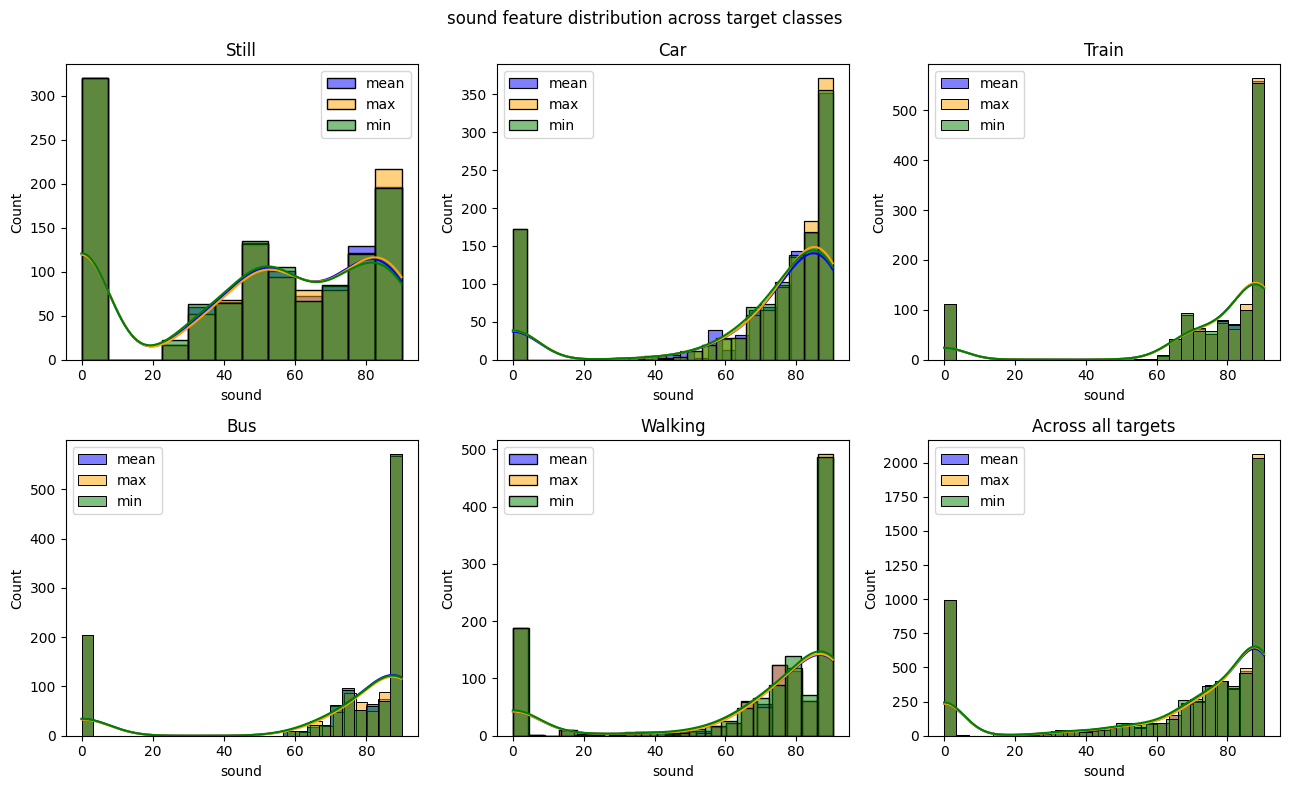

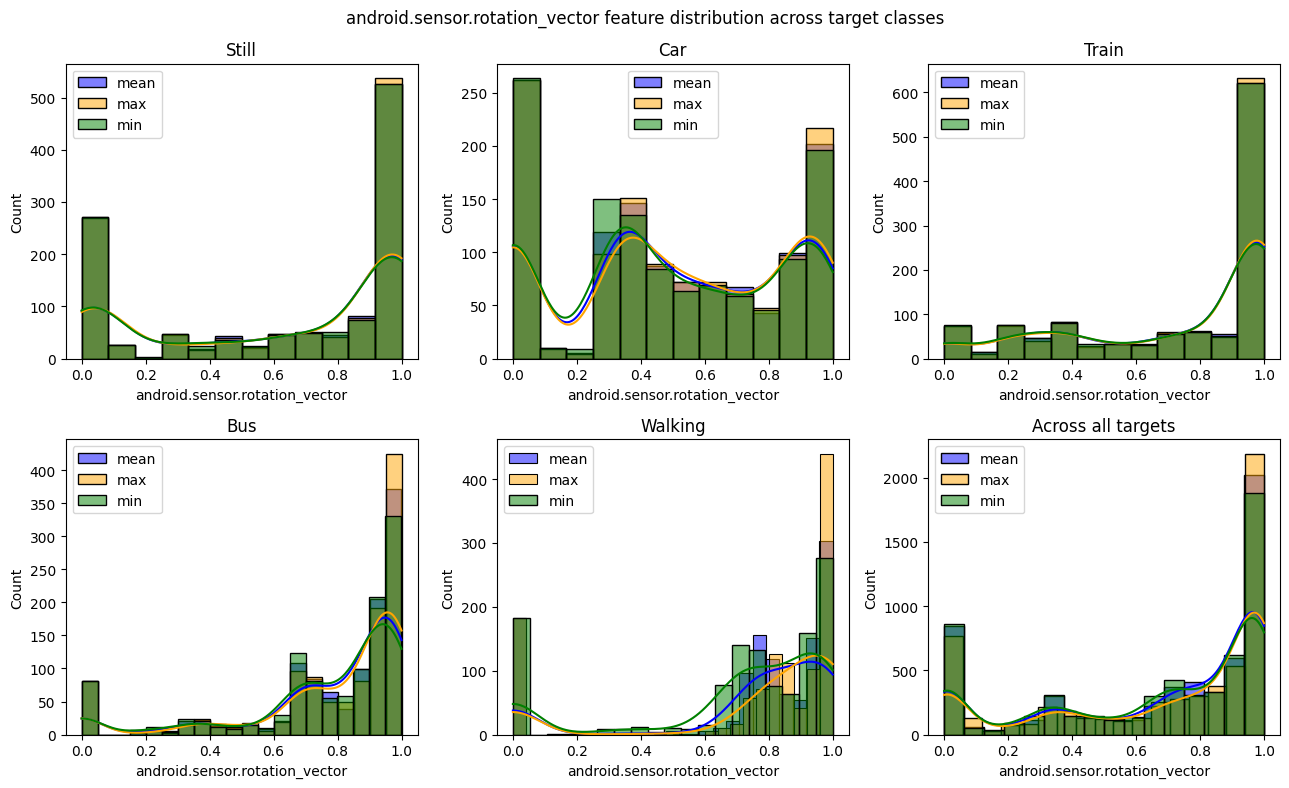

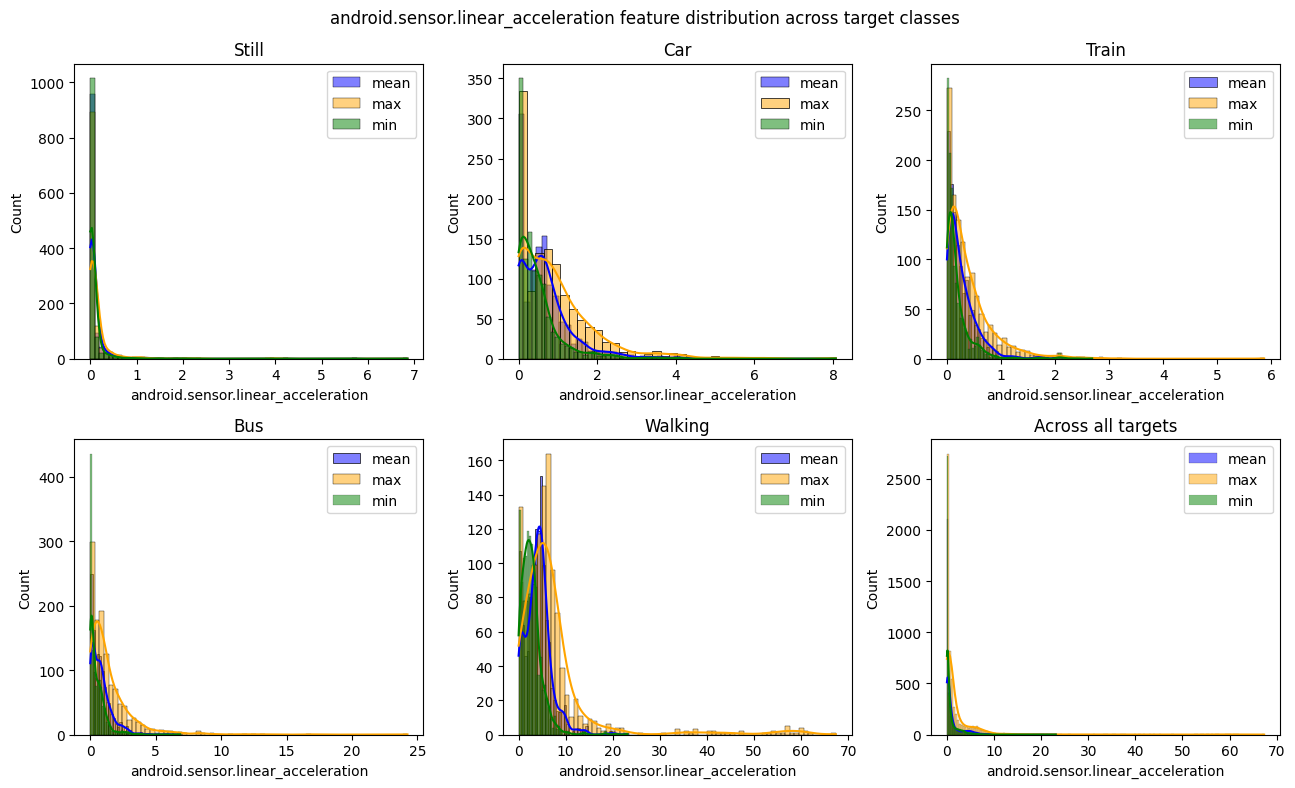

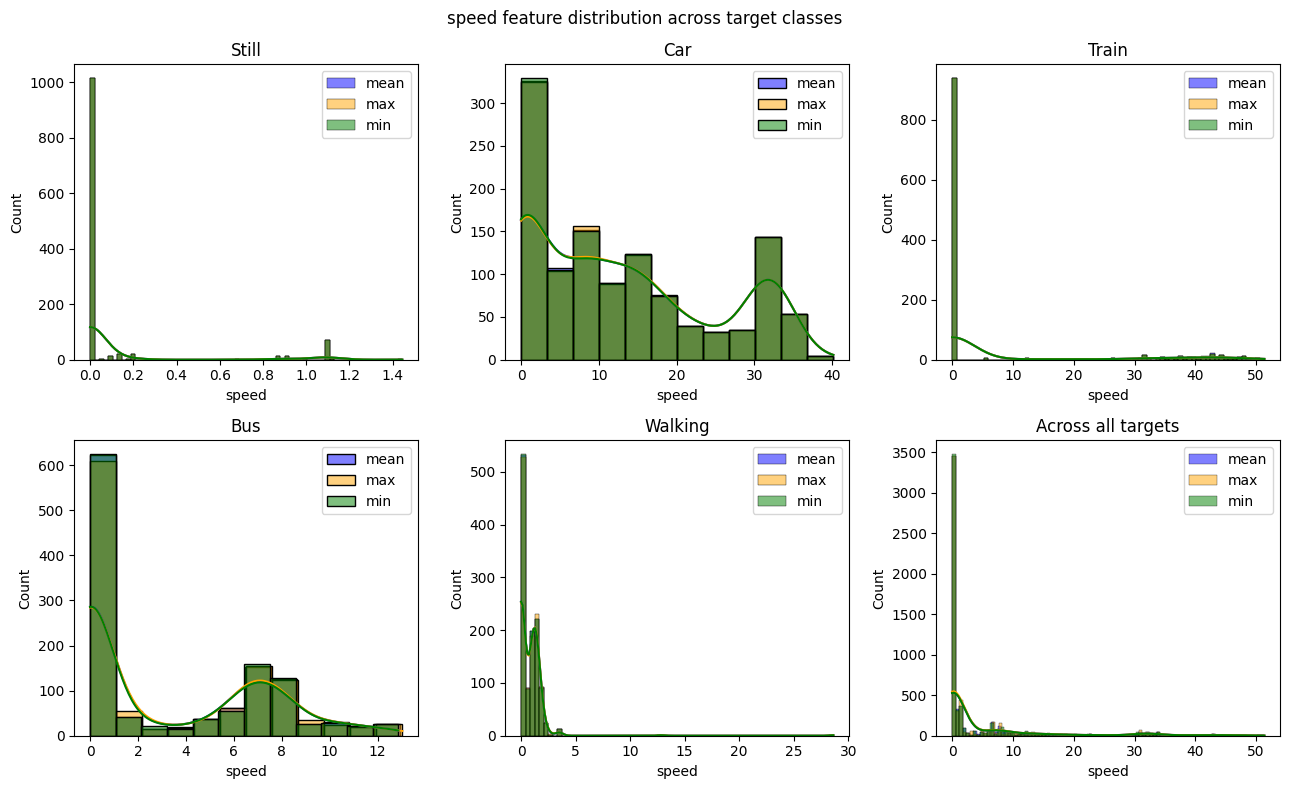

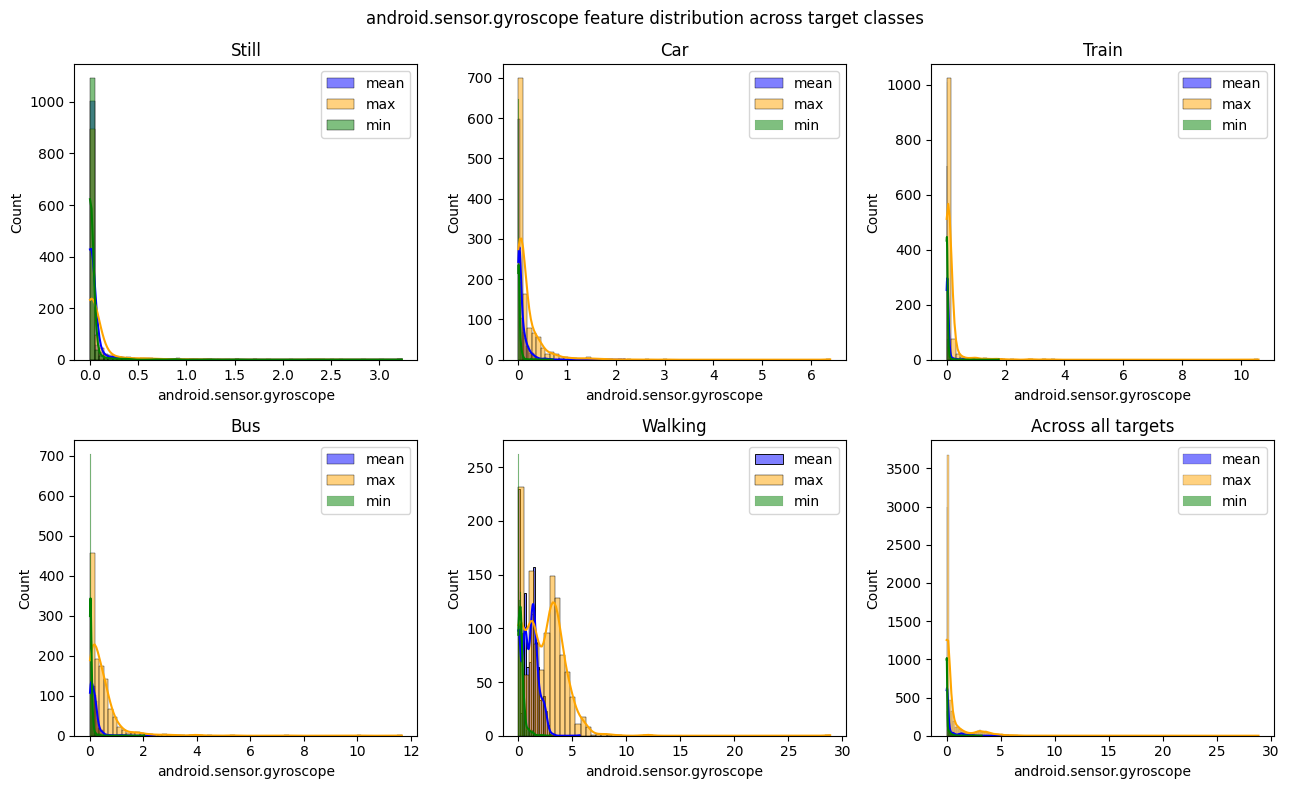

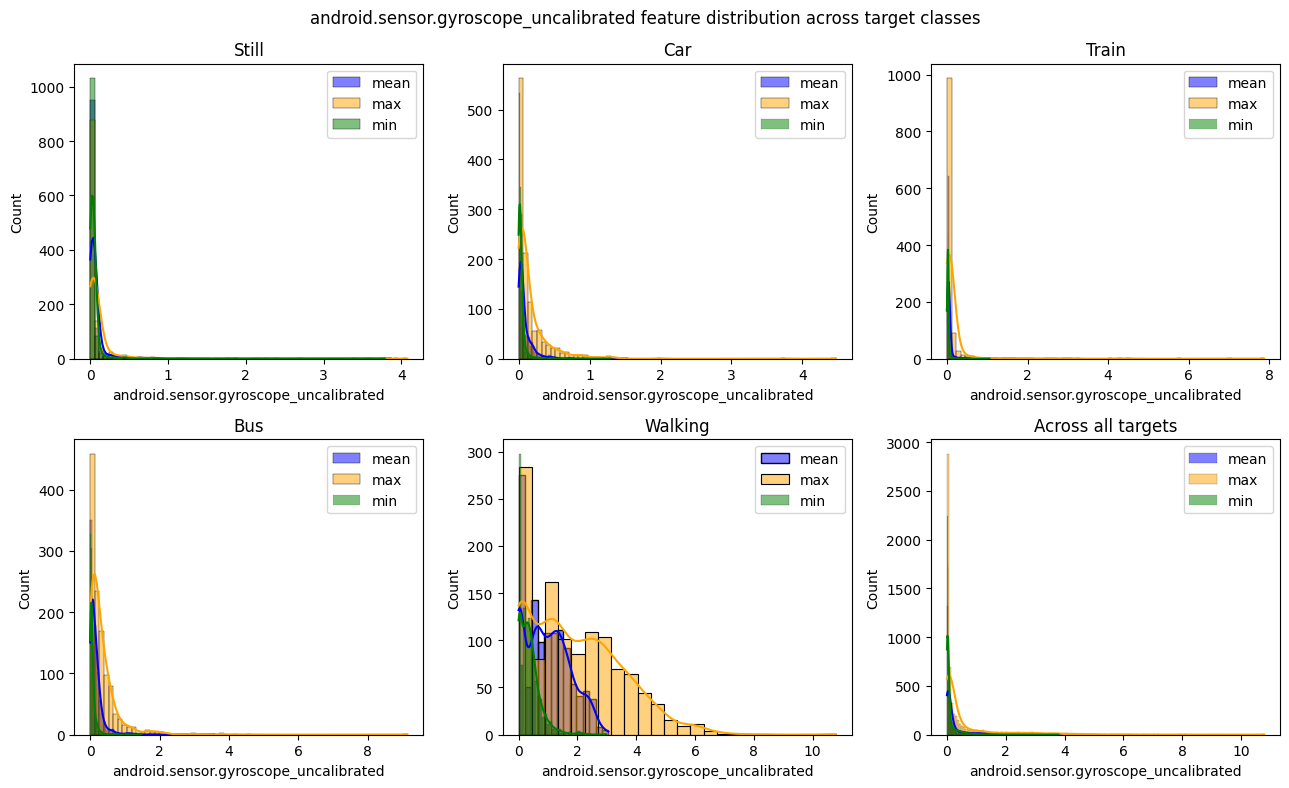

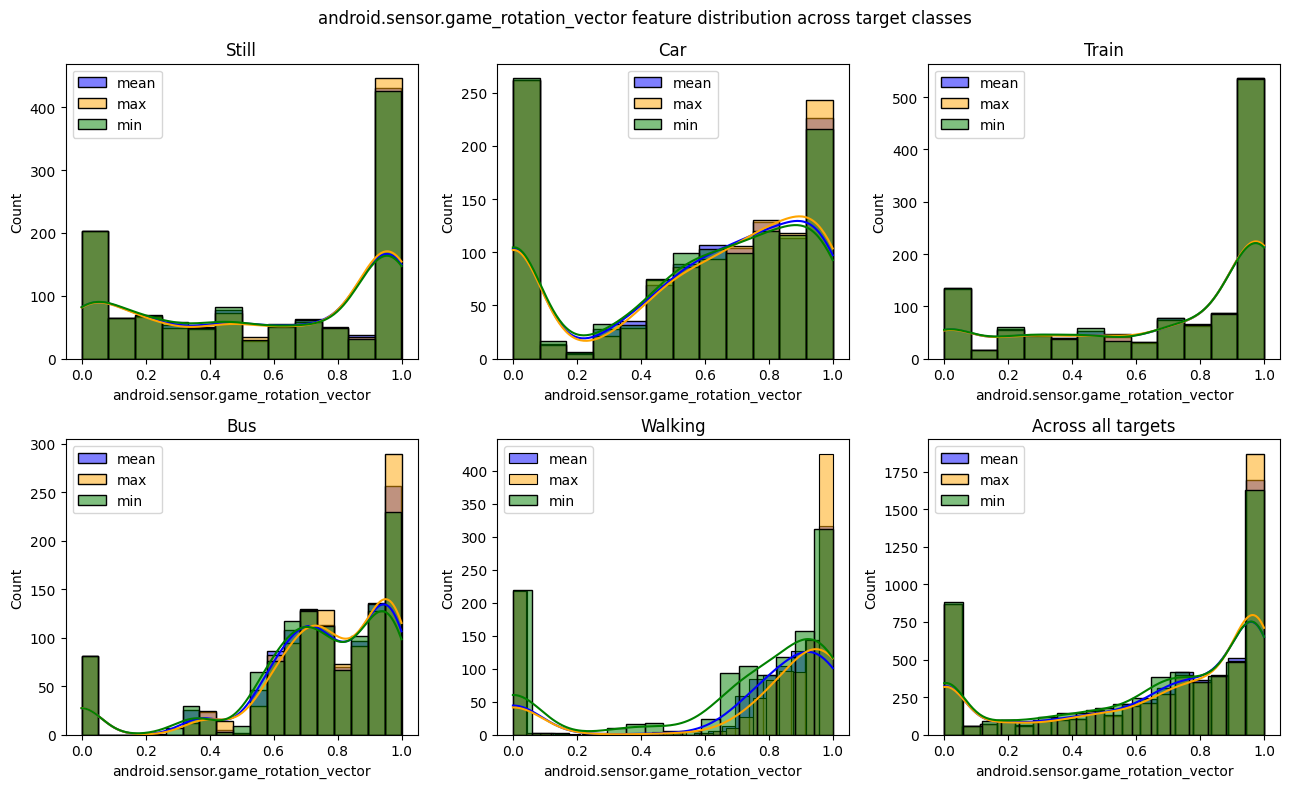

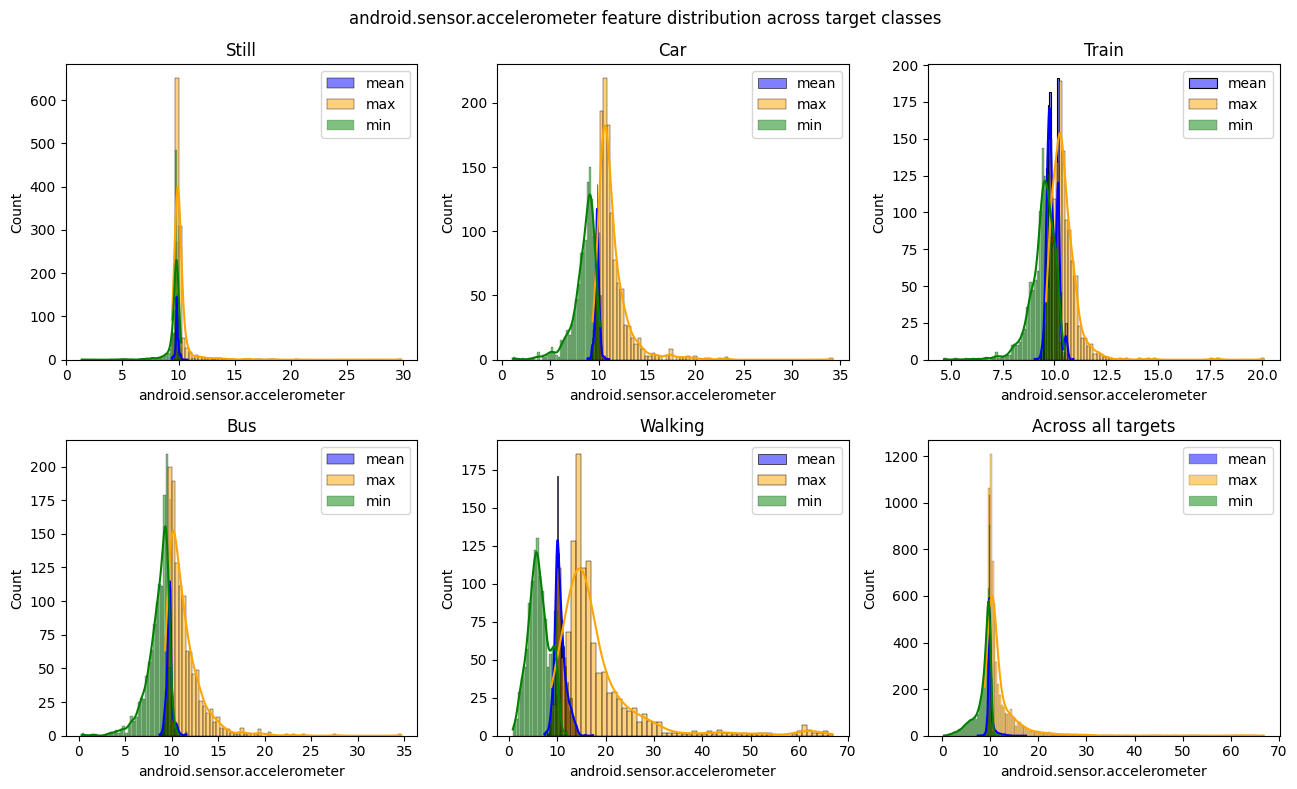

In [12]:
for feature in features:
    draw_plot(df, feature_to_plot=feature)

Следующие признаки сильно скошены:
- android.sensor.gyroscope
- speed
- android.sensor.gyroscope_uncalibrated
- android.sensor.linear_acceleration

Для того, чтобы придать им вид (более менее) нормального распределения (это необходимо, чтобы они при StandardScaling не схлопнулись) логарифмирую их.

Также проведу виноризацию (ограничу неадекватные значения 1 и 99 процентилем с трейна).

In [13]:
skewed_features_raw = ("android.sensor.gyroscope", "speed", "android.sensor.gyroscope_uncalibrated", "android.sensor.linear_acceleration")
skewed_features = [f"{x}#{j}" for x in skewed_features_raw for j in ("mean", "min", "max", "std")]

for feature in skewed_features:
    df[feature] = np.log1p(df[feature])

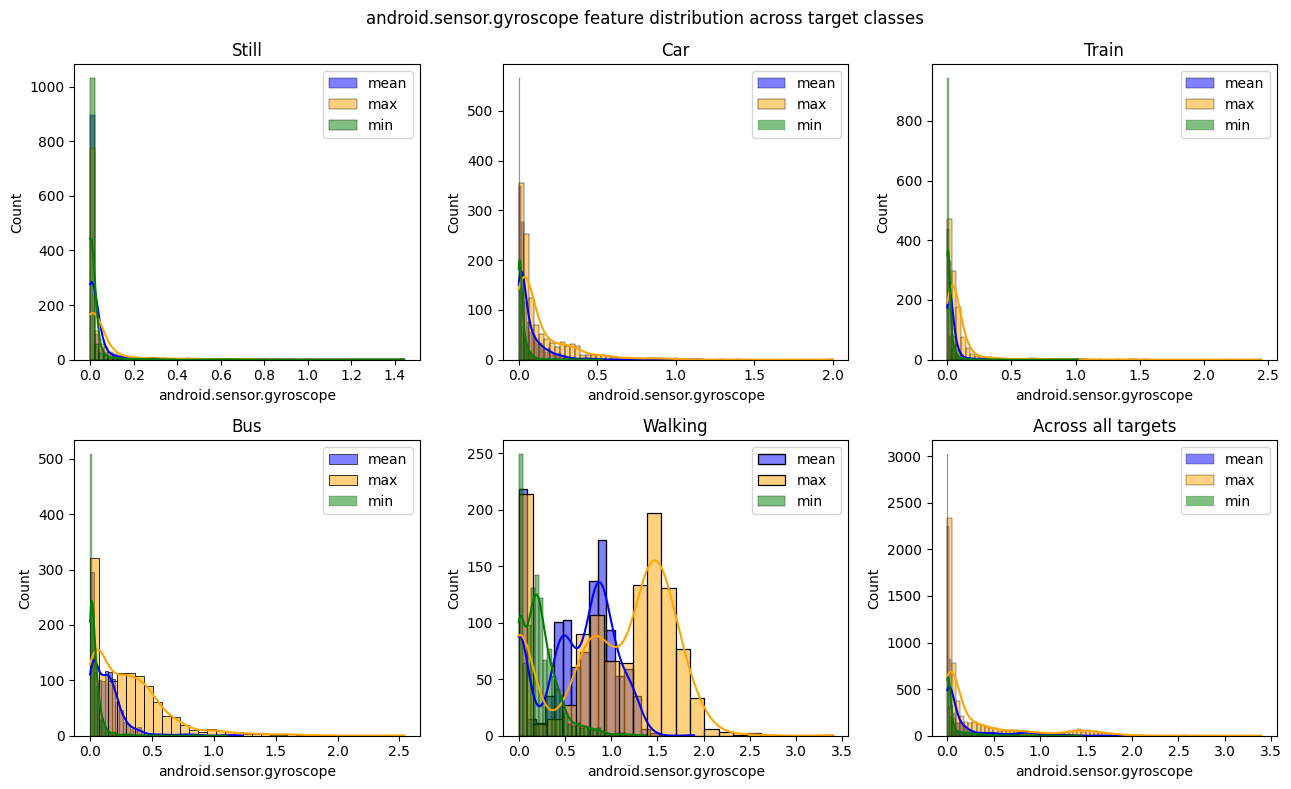

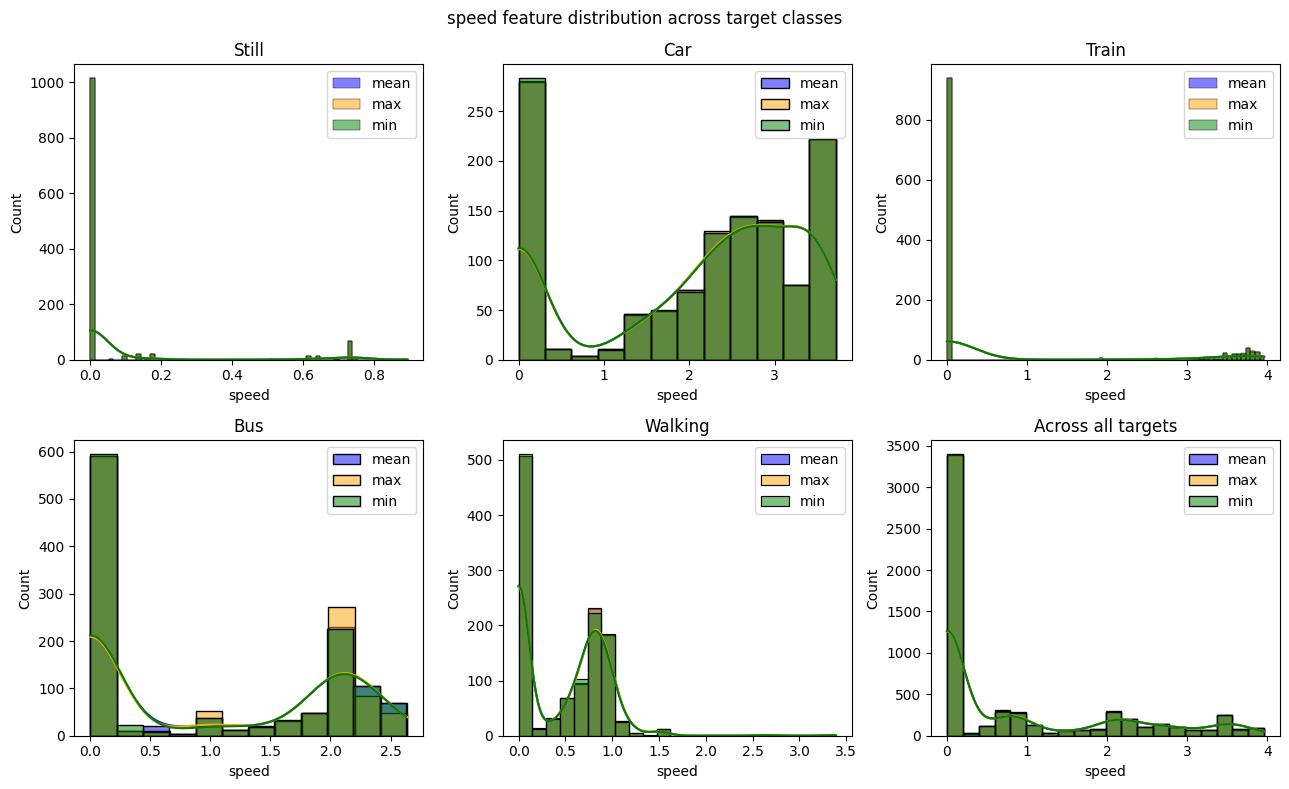

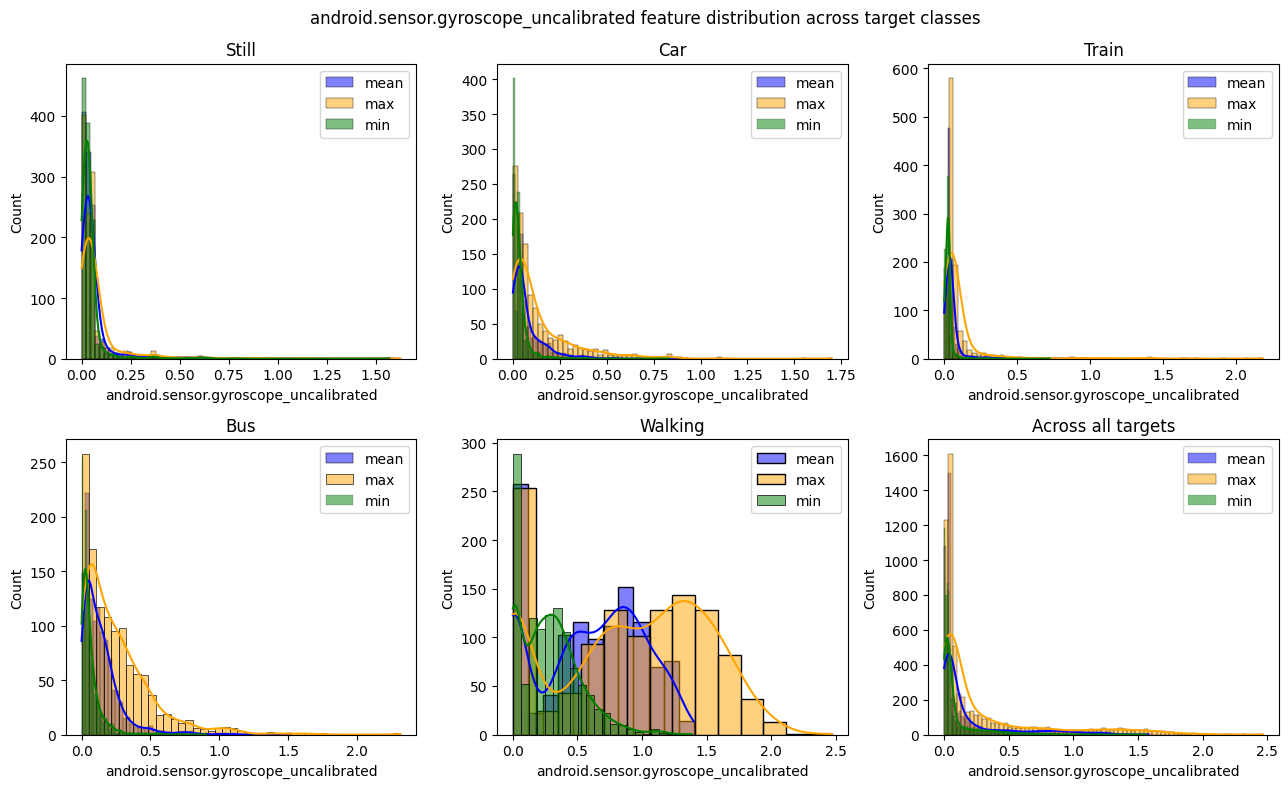

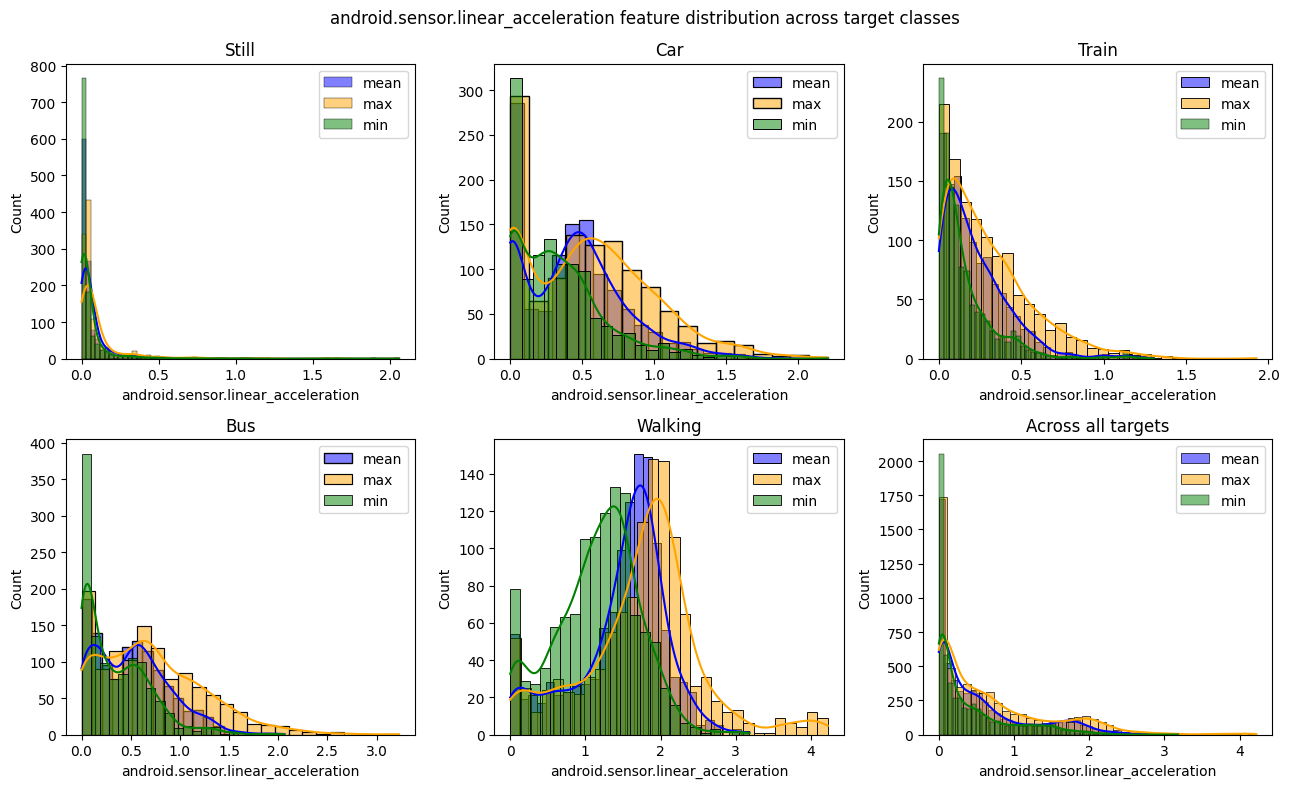

In [14]:
for feature in skewed_features_raw:
    draw_plot(df, feature)

In [15]:
# Разделение на train и test

from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

# Т.к. классы сбалансированы, стратификация необязательна
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

X_train = pd.DataFrame(X_train, columns=X.columns)
X_test = pd.DataFrame(X_test, columns=X.columns)

Проведу винсоризацию данных, чтобы убрать САМЫЕ сильные выбросы. Она заменит их на 1 и 99 процентили. Модель просто поймет, что там очень много.

In [16]:
def winsorizate(dataset: pd.DataFrame, feature: str, percentile_1: (float | int) = None, percentile_99: (float | int) = None) -> tuple:
    """
    На месте заменяет значения признака, которые выше 99 процентиля или ниже 1 процентиля, 99 и 1 процентилем соответственно.\n
    Если не передать процентили, они рассчитаются сами. Полезно для проведения винсоризации тестовых данных на основе тренировочных процентилей.\n
    Возвращает кортеж, в котором первый элемент - 1-й процентиль, а второй - 99-й процентиль.

    Args:
        dataset (pandas.DataFrame): Датафрейм, в котором нужно винзоривать признак.
        feature (str): Индекс признака, которй необходимо винзоривать.
        percentile_1 (float, int, optional): Первый процентиль. При передаче значения в этот аргумент ОБЯЗАТЕЛЬНО нужно передать значение в percentile_99.
        percentile_99 (float, int, optional): Девяносто девятый процентиль. При передаче значения в этот аргумент ОБЯЗАТЕЛЬНО нужно передать значение в percentile_1.
    """

    if (percentile_1 is None) ^ (percentile_99 is None):
        raise ValueError("Both or none percentiles should be provided!")
    
    if percentile_1 is None and percentile_99 is None:
        percentile_1 = np.percentile(dataset[feature], 1)
        percentile_99 = np.percentile(dataset[feature], 99)

    dataset[feature] = np.where(dataset[feature] > percentile_1, dataset[feature], percentile_1)
    dataset[feature] = np.where(dataset[feature] < percentile_99, dataset[feature], percentile_99)

    return (percentile_1, percentile_99)

In [17]:
for feature in X_train.drop(["is_gps_active", "is_mic_active"], axis=1).columns:
    border_low, border_high = winsorizate(X_train, feature)
    winsorizate(X_test, feature, border_low, border_high)

Выведу ниже графики плотности распределения признаков на тренировочном наборе.

In [18]:
def plot_hist(dataset: pd.DataFrame, feature):
        for suffix, color in [("mean", "blue"), ("max", "orange"), ("min", "green")]:
            sns.histplot(dataset[f"{feature}#{suffix}"], fill=True, color=color, kde=True, label=suffix)

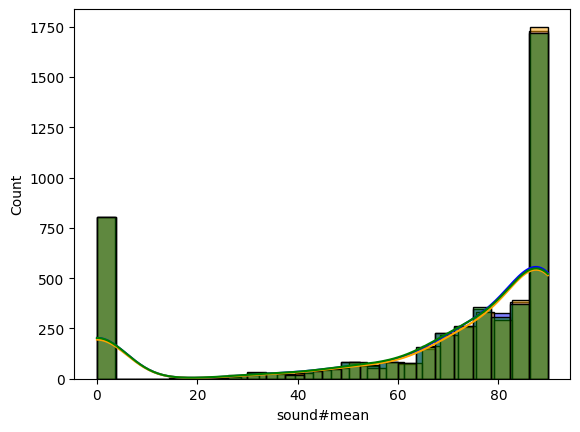

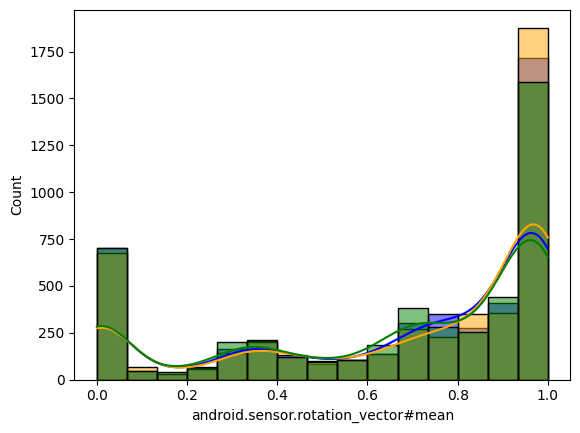

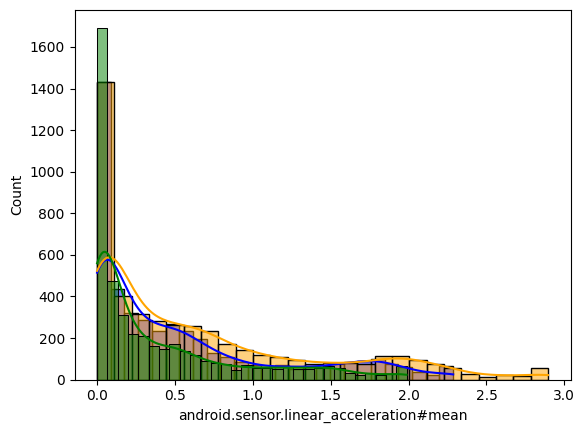

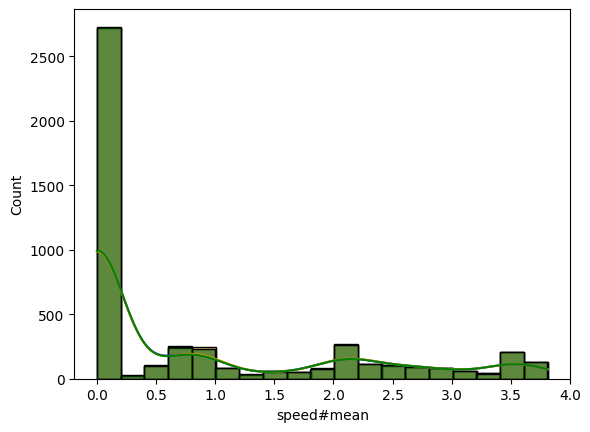

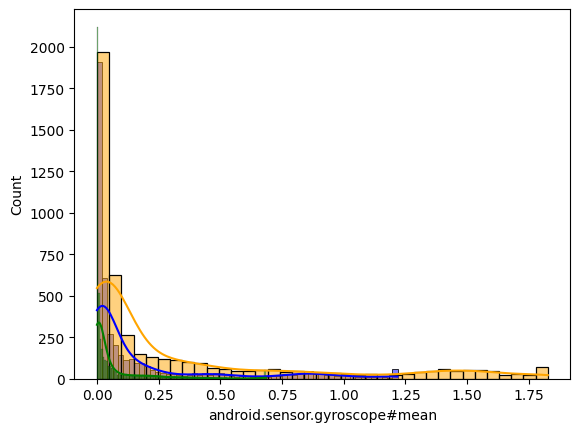

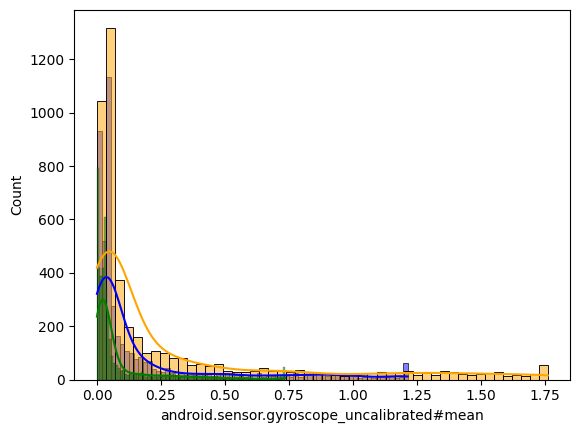

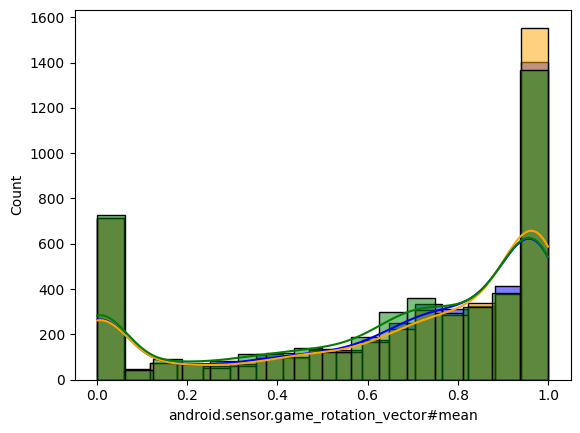

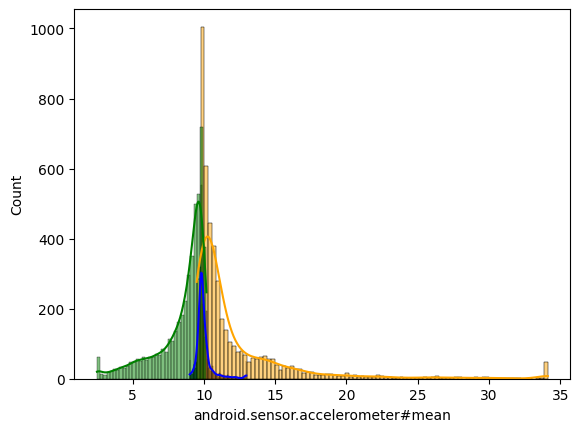

In [19]:
for feature in features:
    plot_hist(X_train, feature)
    plt.show()

In [20]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
android.sensor.accelerometer#mean,4714.0,10.005162,0.607714,9.008141,9.735622,9.851440,10.083017,12.978963
android.sensor.accelerometer#min,4714.0,8.430217,1.765573,2.500433,7.793311,9.131450,9.702267,10.181297
android.sensor.accelerometer#max,4714.0,12.079647,3.951327,9.491053,10.009724,10.601510,12.320768,34.132769
android.sensor.accelerometer#std,4714.0,0.974289,1.458663,0.008170,0.075311,0.363691,1.062924,7.351108
android.sensor.game_rotation_vector#mean,4714.0,0.655932,0.351187,0.000000,0.433155,0.784078,0.956732,0.999820
android.sensor.game_rotation_vector#min,4714.0,0.642382,0.349943,0.000000,0.410433,0.752487,0.951940,0.999759
android.sensor.game_rotation_vector#max,4714.0,0.666715,0.354434,0.000000,0.456582,0.807476,0.962836,0.999993
android.sensor.game_rotation_vector#std,4714.0,0.009787,0.021752,0.000000,0.000069,0.001017,0.007609,0.124558
android.sensor.gyroscope#mean,4714.0,0.186172,0.304930,0.000000,0.007254,0.034237,0.189488,1.217949
android.sensor.gyroscope#min,4714.0,0.062905,0.123611,0.000000,0.002010,0.008502,0.053484,0.684865


Теперь, когда проведена логарифмизация и винсоризация, можно масштабировать данные. Т.к. я их очистил от экстремальных значений, могу смело применять `StandardScaler`.

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.describe()

,android.sensor.accelerometer#mean,android.sensor.accelerometer#min,android.sensor.accelerometer#max,android.sensor.accelerometer#std,android.sensor.game_rotation_vector#mean,android.sensor.game_rotation_vector#min,android.sensor.game_rotation_vector#max,android.sensor.game_rotation_vector#std,android.sensor.gyroscope#mean,android.sensor.gyroscope#min,...,sound#mean,sound#min,sound#max,sound#std,speed#mean,speed#min,speed#max,speed#std,is_gps_active,is_mic_active
count,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,...,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03,4.714000e+03
mean,1.645598e-15,-2.758365e-16,1.318890e-16,2.750828e-17,-4.084792e-16,1.439475e-16,-2.034859e-17,3.316067e-17,-9.043819e-18,1.055112e-17,...,-1.055112e-17,2.735755e-16,-5.350926e-17,2.411685e-17,4.785688e-17,-5.501657e-17,8.591628e-17,4.220449e-17,-2.939241e-17,-2.788511e-17
std,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,...,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00,1.000106e+00
min,-1.640782e+00,-3.358916e+00,-6.551898e-01,-6.624024e-01,-1.867954e+00,-1.835871e+00,-1.881269e+00,-4.500068e-01,-6.106061e-01,-5.089470e-01,...,-2.031484e+00,-2.025117e+00,-2.035665e+00,-5.054037e-01,-7.022596e-01,-6.995001e-01,-7.036967e-01,-2.788602e-01,-8.947688e-01,-2.203611e+00
25%,-4.435770e-01,-3.607747e-01,-5.239109e-01,-6.163684e-01,-6.344220e-01,-6.628907e-01,-5.929310e-01,-4.468439e-01,-5.868132e-01,-4.926853e-01,...,-2.253616e-01,-2.322047e-01,-2.141061e-01,-5.054037e-01,-7.022596e-01,-6.995001e-01,-7.036967e-01,-2.788602e-01,-8.947688e-01,4.538006e-01
50%,-2.529771e-01,3.972124e-01,-3.741259e-01,-4.186456e-01,3.649331e-01,3.146697e-01,3.971856e-01,-4.032244e-01,-4.983172e-01,-4.401634e-01,...,4.379903e-01,4.346717e-01,4.420806e-01,-4.900901e-01,-7.022596e-01,-6.995001e-01,-7.036967e-01,-2.788602e-01,-8.947688e-01,4.538006e-01
75%,1.281257e-01,7.205505e-01,6.102912e-02,6.077085e-02,8.566141e-01,8.846874e-01,8.355672e-01,-1.001580e-01,1.087501e-02,-7.622110e-02,...,7.538931e-01,7.608384e-01,7.461462e-01,1.018898e-01,7.524149e-01,7.553548e-01,7.500187e-01,-2.788602e-01,1.117607e+00,4.538006e-01
max,4.893940e+00,9.918963e-01,5.581786e+00,4.372151e+00,9.793206e-01,1.021351e+00,9.404105e-01,5.276917e+00,3.384008e+00,5.032116e+00,...,7.576099e-01,7.644965e-01,7.498305e-01,5.308701e+00,2.468117e+00,2.468149e+00,2.464784e+00,5.933587e+00,1.117607e+00,4.538006e-01


Можем видеть, что $\text{mean} \approx 0$, а $\text{std} \approx 1$. Это значит, что `StandardScaler` сработал как надо!

Объединю X_train_scaled с y_train, X_test_scaled с y_test и экспортирую 2 таблицы в формате .csv

In [22]:
preprocessed_train = pd.concat([X_train_scaled, y_train], axis=1).reset_index(drop=True)
preprocessed_train

,android.sensor.accelerometer#mean,android.sensor.accelerometer#min,android.sensor.accelerometer#max,android.sensor.accelerometer#std,android.sensor.game_rotation_vector#mean,android.sensor.game_rotation_vector#min,android.sensor.game_rotation_vector#max,android.sensor.game_rotation_vector#std,android.sensor.gyroscope#mean,android.sensor.gyroscope#min,...,sound#min,sound#max,sound#std,speed#mean,speed#min,speed#max,speed#std,is_gps_active,is_mic_active,target
0,-0.293209,0.775146,-0.561845,-0.657924,0.031191,0.069472,0.001082,-0.440462,-0.604136,-0.500333,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Still
1,-0.293507,0.092437,-0.381824,-0.302621,0.711018,0.735989,0.685749,-0.283626,-0.320443,-0.436184,...,0.763070,0.749831,-0.467588,-0.365066,-0.362264,-0.366725,-0.278860,1.117607,0.453801,Car
2,0.707581,-3.358916,2.205880,3.134384,-1.867954,-1.835871,-1.881269,-0.450007,-0.610606,-0.508947,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Walking
3,-0.235726,-0.620236,0.397666,0.549972,-0.640595,-0.604148,-0.665152,-0.206262,0.043289,-0.192723,...,0.372371,0.360114,-0.486168,1.214972,1.217969,1.212270,-0.278860,1.117607,0.453801,Car
4,-0.446631,-2.169060,1.807620,1.849592,-0.004798,-0.129416,0.157368,1.344369,3.282965,5.032116,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Walking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4709,3.717294,-3.309513,4.235040,3.268198,0.186207,0.067323,0.288757,1.939873,3.181807,4.294795,...,0.764496,0.749831,0.890323,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,0.453801,Walking
4710,-0.261603,0.790975,-0.541204,-0.654372,-0.699277,-0.663051,-0.723277,-0.449828,-0.604129,-0.499068,...,0.328893,0.314670,0.971191,-0.701180,-0.698420,-0.702617,-0.249594,1.117607,0.453801,Still
4711,-0.556319,0.668009,-0.599015,-0.651566,0.544479,0.582516,0.512598,-0.410060,-0.536274,-0.462197,...,0.662314,0.647571,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,0.453801,Bus
4712,-0.319443,0.755125,-0.562034,-0.656116,-1.717925,-1.686380,-1.731214,-0.438420,-0.605230,-0.508947,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Still


In [23]:
preprocessed_test = pd.concat([X_test_scaled, y_test], axis=1).reset_index(drop=True)
preprocessed_test

,android.sensor.accelerometer#mean,android.sensor.accelerometer#min,android.sensor.accelerometer#max,android.sensor.accelerometer#std,android.sensor.game_rotation_vector#mean,android.sensor.game_rotation_vector#min,android.sensor.game_rotation_vector#max,android.sensor.game_rotation_vector#std,android.sensor.gyroscope#mean,android.sensor.gyroscope#min,...,sound#min,sound#max,sound#std,speed#mean,speed#min,speed#max,speed#std,is_gps_active,is_mic_active,target
0,-0.436235,-1.122010,0.983083,0.553638,-1.867954,-1.835871,-1.881269,-0.450007,-0.610606,-0.508947,...,-0.494070,-0.507008,-0.088024,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,0.453801,Car
1,-0.214522,0.412149,-0.333229,-0.425307,-0.150215,-0.128221,-0.163275,-0.081550,-0.497130,-0.270963,...,0.568616,0.554019,-0.110750,1.489391,1.487523,1.491376,0.576686,1.117607,0.453801,Bus
2,0.982556,0.714261,-0.125028,-0.195140,0.959326,1.001460,0.920113,-0.415077,0.470705,-0.105504,...,-0.179326,-0.192755,-0.505404,1.001316,1.004287,0.998756,-0.278860,1.117607,0.453801,Bus
3,0.287063,0.979399,-0.474881,-0.658941,0.967228,1.009316,0.928036,-0.448833,-0.589566,-0.499081,...,0.356718,0.342453,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,0.453801,Still
4,-0.694534,-0.568832,-0.026375,0.240228,0.919321,0.924100,0.898261,-0.206779,-0.091267,0.297765,...,-2.025117,-2.035665,-0.505404,1.506141,1.509174,1.503248,-0.278860,1.117607,-2.203611,Car
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1174,-0.360394,0.536868,-0.463456,-0.536967,-0.827730,-0.800586,-0.841367,-0.385063,-0.536562,-0.496767,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Bus
1175,-0.076452,0.290480,-0.286292,-0.518978,-1.867954,-1.835871,-1.881269,-0.450007,-0.610606,-0.508947,...,-0.128148,-0.141657,2.785882,0.339567,0.342455,0.337443,-0.278860,1.117607,0.453801,Car
1176,0.337124,0.089774,-0.062852,0.904069,-1.867954,-1.835871,-1.881269,-0.450007,-0.610606,-0.508947,...,-2.025117,-2.035665,-0.505404,-0.702260,-0.699500,-0.703697,-0.278860,-0.894769,-2.203611,Walking
1177,-0.340426,-0.129551,-0.192307,-0.101083,-0.031862,-0.000457,-0.054882,-0.286084,-0.526601,-0.451170,...,-2.025117,-2.035665,-0.505404,2.236435,2.239559,2.233060,0.991587,1.117607,-2.203611,Car


In [24]:
# Сохраняю полученные таблицы

preprocessed_train.to_csv("clean/clean_train.csv")
preprocessed_test.to_csv("clean/clean_test.csv")

### Экспорт параметров предобработки для бэкенда

Сериализую и сохраню процентили для винзоризатора, обученный StandardScaler и порядок колонок, чтобы бэкенд мог делать предобработку сырых признаков на этапе инференса.

In [25]:
import pickle

df_raw = pd.read_csv("raw/Dthird.csv")
df_raw = df_raw.drop(["time", "android.sensor.orientation#min", "android.sensor.orientation#max", "android.sensor.orientation#mean", "android.sensor.orientation#std"], axis=1)
df_raw["is_gps_active"] = (df_raw["speed#mean"] > 0).astype(int)
df_raw["is_mic_active"] = (df_raw["sound#mean"] > 0).astype(int)

In [26]:
skewed_features_raw = ("android.sensor.gyroscope", "speed", "android.sensor.gyroscope_uncalibrated", "android.sensor.linear_acceleration")
skewed_features = [f"{x}#{j}" for x in skewed_features_raw for j in ("mean", "min", "max", "std")]
for feature in skewed_features:
    df_raw[feature] = np.log1p(df_raw[feature])

In [27]:
X_raw = df_raw.drop("target", axis=1)
y_raw = df_raw["target"]
X_train_raw, _, _, _ = train_test_split(X_raw, y_raw, test_size=0.2, random_state=101)

In [28]:
percentiles = {}
continuous_features = X_train_raw.drop(["is_gps_active", "is_mic_active"], axis=1).columns
for feature in continuous_features:
    p1 = np.percentile(X_train_raw[feature], 1)
    p99 = np.percentile(X_train_raw[feature], 99)
    percentiles[feature] = (p1, p99)

In [29]:
# сохранение
preprocessor_path = "../backend/preprocessor.pkl"
with open(preprocessor_path, "wb") as f:
    pickle.dump((percentiles, scaler, list(X.columns)), f, protocol=5)